# Hands-On Data Lab Implementation
**Task 2** - AI ML Research Specialist Internship

A reproducible data-analysis lab on a synthetic retail dataset (customers, products, orders).

| Part | Objective |
|---|---|
| 1 | Set up and verify the Data Science environment |
| 2 | Work with data using Pandas and NumPy |
| 3 | Data cleaning |
| 4 | Data visualisation (Matplotlib + Seaborn) |
| 5 | Basic data analysis |
| 6 | Observations and insights |

**Reproduce:** `pip install -r requirements.txt` -> `python src/generate_data.py` -> run this notebook top to bottom.

## Part 1 - Set up the Data Science environment
Installation steps are in `SETUP.md`. The cell below imports every essential library, fixes the random seed and prints versions as proof of a working setup.

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

SEED = 7
np.random.seed(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
METRICS = {}          # key results are collected here and saved for the report

def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

print("Python      ", sys.version.split()[0])
for lib in (np, pd, matplotlib, sns, scipy, sklearn):
    print(f"{lib.__name__:<12}", lib.__version__)

Python       3.12.3
numpy        2.4.4
pandas       3.0.2
matplotlib   3.10.8
seaborn      0.13.2
scipy        1.17.1
sklearn      1.8.0


## Part 2 - Work with data using Pandas and NumPy
### 2A. Load and inspect the raw data

In [2]:
customers = pd.read_csv(ROOT / "data" / "customers.csv")
products  = pd.read_csv(ROOT / "data" / "products.csv")
orders    = pd.read_csv(ROOT / "data" / "orders.csv")
for name, d in {"customers": customers, "products": products, "orders": orders}.items():
    print(f"{name:<10} rows={d.shape[0]:>5}  cols={d.shape[1]}")
orders.head()

customers  rows=  400  cols=5
products   rows=   40  cols=5
orders     rows= 5060  cols=8


,order_id,order_date,customer_id,product_id,quantity,discount,payment_method,status
0,ORD00001,2024-12-21,CU0146,P008,1.0,0.1,UPI,Delivered
1,ORD00002,2025-12-20,CU0343,P026,3.0,0.15,Credit Card,Delivered
2,ORD00003,2024-12-21,CU0065,P017,3.0,0.15,UPI,Delivered
3,ORD00004,2025-11-26,CU0195,P006,5.0,0.0,Credit Card,Delivered
4,ORD00005,2025-07-17,CU0364,P011,3.0,0.05,Cash on Delivery,Delivered


In [3]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 5060 entries, 0 to 5059
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        5060 non-null   str    
 1   order_date      5060 non-null   str    
 2   customer_id     5060 non-null   str    
 3   product_id      5060 non-null   str    
 4   quantity        4978 non-null   float64
 5   discount        5060 non-null   str    
 6   payment_method  5020 non-null   str    
 7   status          5060 non-null   str    
dtypes: float64(1), str(7)
memory usage: 316.4 KB


In [4]:
orders.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,5060,5000,ORD00162,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,5060,844,2025-11-07,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,5060,400,CU0033,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,5060,40,P015,156,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,4978.0,NaN,NaN,NaN,2.992567,1.418662,-2.0,2.0,3.0,4.0,5.0
discount,5060,10,0.0,2112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,5020,8,UPI,1964,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,5060,3,Delivered,4416,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Selection, filtering and sorting

In [5]:
# column selection, label-based (loc) and position-based (iloc) selection
print(orders[["order_id", "quantity"]].head(3), "\n")
print(orders.loc[10:12, ["order_id", "status"]], "\n")
print(orders.iloc[0:3, 0:4])

   order_id  quantity
0  ORD00001       1.0
1  ORD00002       3.0
2  ORD00003       3.0 

    order_id     status
10  ORD00011  Delivered
11  ORD00012   Returned
12  ORD00013   Returned 

   order_id  order_date customer_id product_id
0  ORD00001  2024-12-21      CU0146       P008
1  ORD00002  2025-12-20      CU0343       P026
2  ORD00003  2024-12-21      CU0065       P017


In [6]:
# boolean filtering, isin, query, multiple conditions
returned = orders[orders["status"] == "Returned"]
big_upi  = orders[(orders["payment_method"] == "UPI") & (orders["quantity"] >= 4)]
metro    = customers[customers["city"].isin(["Pune", "Mumbai"])]
print("Returned orders:", len(returned), "| UPI orders with qty>=4:", len(big_upi), "| Pune/Mumbai customers:", len(metro))
orders.query("discount == '0.2' and status == 'Delivered'").head(3)

Returned orders: 454 | UPI orders with qty>=4: 773 | Pune/Mumbai customers: 114


,order_id,order_date,customer_id,product_id,quantity,discount,payment_method,status
6,ORD00007,2025-04-28,CU0243,P004,3.0,0.2,UPI,Delivered
15,ORD00016,2024-10-08,CU0348,P023,4.0,0.2,Credit Card,Delivered
21,ORD00022,2024-12-17,CU0284,P035,2.0,0.2,Credit Card,Delivered


In [7]:
# sorting
orders.sort_values(["quantity", "order_id"], ascending=[False, True]).head(5)

,order_id,order_date,customer_id,product_id,quantity,discount,payment_method,status
3,ORD00004,2025-11-26,CU0195,P006,5.0,0.0,Credit Card,Delivered
7,ORD00008,2024-04-12,CU0240,P007,5.0,0.15,Cash on Delivery,Returned
18,ORD00019,2025-12-17,CU0353,P015,5.0,0.1,Debit Card,Delivered
19,ORD00020,2025-11-02,CU0207,P003,5.0,0.0,Debit Card,Delivered
30,ORD00031,2025-05-30,CU0188,P012,5.0,0.2,Credit Card,Delivered


### Grouping and aggregation (raw data)

In [8]:
print(orders.groupby("status").size().rename("orders"))
orders.groupby("payment_method", dropna=False).agg(orders=("order_id", "count"), avg_qty=("quantity", "mean")).round(2)

status
Cancelled     190
Delivered    4416
Returned      454
Name: orders, dtype: int64


,orders,avg_qty
payment_method,,
Cash on Delivery,514,2.99
Credit Card,1451,3.03
Debit Card,991,2.93
UPI,1964,3.00
cash on delivery,8,2.25
credit card,33,3.06
debit card,23,2.91
upi,36,2.91
NaN,40,2.95


### NumPy operations

In [9]:
qty = orders["quantity"].to_numpy()
print("dtype:", qty.dtype, "| NaNs:", int(np.isnan(qty).sum()))
valid = qty[~np.isnan(qty)]
print("mean %.2f | median %.1f | std %.2f" % (valid.mean(), np.median(valid), valid.std(ddof=1)))
print("quartiles:", np.percentile(valid, [25, 50, 75]))
print("min:", valid.min(), "(a negative quantity is invalid - handled in Part 3)")

# 2-D arrays, axis operations, broadcasting, np.where
grid = np.arange(12).reshape(3, 4)
print("\ngrid:\n", grid, "\ncolumn sums:", grid.sum(axis=0), "| row means:", grid.mean(axis=1))
prices = np.array([100., 200., 300.]); qtys = np.array([[1], [2]])
print("broadcast (2x1)*(3,) ->\n", qtys * prices)
print("np.where:", np.where(valid[:8] >= 3, "bulk", "regular"))

# vectorised vs loop
x = np.random.default_rng(SEED).normal(size=1_000_000)
t0 = time.perf_counter(); s1 = sum(v * v for v in x);  t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); s2 = np.dot(x, x);           t_vec  = time.perf_counter() - t0
print(f"\nsum of squares: loop {t_loop:.3f}s vs NumPy {t_vec:.5f}s  (~{t_loop / t_vec:,.0f}x faster)")
METRICS["numpy_speedup"] = round(t_loop / t_vec)

dtype: float64 | NaNs: 82
mean 2.99 | median 3.0 | std 1.42
quartiles: [2. 3. 4.]
min: -2.0 (a negative quantity is invalid - handled in Part 3)

grid:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] 
column sums: [12 15 18 21] | row means: [1.5 5.5 9.5]
broadcast (2x1)*(3,) ->
 [[100. 200. 300.]
 [200. 400. 600.]]
np.where: ['regular' 'bulk' 'bulk' 'bulk' 'bulk' 'regular' 'bulk' 'bulk']



sum of squares: loop 0.138s vs NumPy 0.00093s  (~148x faster)


## Part 3 - Data cleaning
Steps: **detect** issues -> **fix** with documented rules -> **validate** with assertions.

| Issue | Rule applied |
|---|---|
| Duplicate rows | `drop_duplicates()` |
| Missing / invalid quantity (<=0) | set invalid to NaN, impute with the product median |
| Discount mixed `0.1` and `"10%"` | strip `%`, convert to a fraction (float) |
| Dates in two formats | parse ISO first, then `dd/mm/yyyy` |
| Inconsistent text (case, spaces) | `strip()` and a mapping to canonical labels |
| Missing categories | explicit `"Unknown"` label (not silently dropped) |
| Wrong dtype (`"Rs 1,299"` price) | remove symbols, convert to numeric |
| Invalid age (<18 or >100) / missing | set to NaN, impute with median |

In [10]:
iso = r"\d{4}-\d{2}-\d{2}"
issues = {
  "orders: duplicate rows":                  int(orders.duplicated().sum()),
  "orders: missing quantity":                int(orders["quantity"].isna().sum()),
  "orders: invalid quantity (<= 0)":         int((orders["quantity"] <= 0).sum()),
  "orders: discount stored as 'x%' text":    int(orders["discount"].astype(str).str.contains("%").sum()),
  "orders: dates not in ISO format":         int((~orders["order_date"].str.match(iso)).sum()),
  "orders: payment_method case variants":    int(orders["payment_method"].nunique() - orders["payment_method"].str.lower().nunique()),
  "orders: missing payment_method":          int(orders["payment_method"].isna().sum()),
  "customers: city case/space variants":     int(customers["city"].nunique() - customers["city"].str.strip().str.title().nunique()),
  "customers: missing age":                  int(customers["age"].isna().sum()),
  "customers: invalid age (< 18)":           int((customers["age"] < 18).sum()),
  "customers: missing segment":              int(customers["segment"].isna().sum()),
  "products: price stored as text ('Rs')":   int(products["unit_price"].astype(str).str.contains("Rs").sum()),
}
issues_df = pd.Series(issues, name="count").to_frame()
METRICS["issues"] = issues
issues_df

,count
orders: duplicate rows,60
orders: missing quantity,82
orders: invalid quantity (<= 0),6
orders: discount stored as 'x%' text,150
orders: dates not in ISO format,123
orders: payment_method case variants,4
orders: missing payment_method,40
customers: city case/space variants,12
customers: missing age,24
customers: invalid age (< 18),3


In [11]:
def clean_orders(df):
    df = df.drop_duplicates().copy()
    # dates: two formats
    d1 = pd.to_datetime(df["order_date"], format="%Y-%m-%d", errors="coerce")
    d2 = pd.to_datetime(df["order_date"], format="%d/%m/%Y", errors="coerce")
    df["order_date"] = d1.fillna(d2)
    # discount: "10%" -> 0.10, "0.1" -> 0.1
    s = df["discount"].astype(str).str.strip()
    pct = s.str.endswith("%")
    val = pd.to_numeric(s.str.rstrip("%"), errors="coerce")
    df["discount"] = val.where(~pct, val / 100)
    # quantity: invalid -> NaN -> product median -> overall median
    df.loc[df["quantity"] <= 0, "quantity"] = np.nan
    df["quantity"] = df["quantity"].fillna(df.groupby("product_id")["quantity"].transform("median"))
    df["quantity"] = df["quantity"].fillna(df["quantity"].median()).round().astype(int)
    # payment method: canonical labels
    canon = {"credit card": "Credit Card", "upi": "UPI", "debit card": "Debit Card", "cash on delivery": "Cash on Delivery"}
    df["payment_method"] = df["payment_method"].str.strip().str.lower().map(canon).fillna("Unknown")
    return df.reset_index(drop=True)

def clean_customers(df):
    df = df.copy()
    df["city"] = df["city"].str.strip().str.title()
    df["segment"] = df["segment"].fillna("Unknown")
    df.loc[~df["age"].between(18, 100), "age"] = np.nan
    df["age"] = df["age"].fillna(df["age"].median()).astype(int)
    df["signup_date"] = pd.to_datetime(df["signup_date"], format="%Y-%m-%d")
    return df

def clean_products(df):
    df = df.copy()
    txt = df["unit_price"].astype(str).str.replace(r"[^0-9.]", "", regex=True)
    df["unit_price"] = pd.to_numeric(txt)
    return df

orders_c, customers_c, products_c = clean_orders(orders), clean_customers(customers), clean_products(products)
print("orders:", orders.shape, "->", orders_c.shape)

orders: (5060, 8) -> (5000, 8)


In [12]:
# validation: the cleaning rules must hold, otherwise the cell fails loudly
assert orders_c["order_id"].is_unique
assert orders_c[["order_date", "discount", "quantity"]].notna().all().all()
assert (orders_c["quantity"] > 0).all() and orders_c["discount"].between(0, 1).all()
assert set(orders_c["payment_method"]) == {"Credit Card", "UPI", "Debit Card", "Cash on Delivery", "Unknown"}
assert customers_c["city"].nunique() == 6 and customers_c["age"].between(18, 100).all()
assert pd.api.types.is_numeric_dtype(products_c["unit_price"])
assert orders_c["customer_id"].isin(customers_c["customer_id"]).all()    # referential integrity
assert orders_c["product_id"].isin(products_c["product_id"]).all()
print("All data-quality checks passed")

before_after = pd.DataFrame({
    "before": [orders.shape[0], orders["quantity"].isna().sum(), orders["payment_method"].nunique(), customers["city"].nunique()],
    "after":  [orders_c.shape[0], orders_c["quantity"].isna().sum(), orders_c["payment_method"].nunique(), customers_c["city"].nunique()],
}, index=["order rows", "missing quantity", "payment_method labels", "city labels"])
METRICS["rows_before"], METRICS["rows_after"] = int(orders.shape[0]), int(orders_c.shape[0])
before_after

All data-quality checks passed


,before,after
order rows,5060,5000
missing quantity,82,0
payment_method labels,8,5
city labels,18,6


## Part 2B - Merge, transform and aggregate the clean data
Back to Objective 2: merging, transformation and aggregation, now on trustworthy data.

In [13]:
df = (orders_c
      .merge(customers_c, on="customer_id", how="left", validate="m:1")
      .merge(products_c,  on="product_id",  how="left", validate="m:1"))
assert len(df) == len(orders_c)                       # a many-to-one merge must not add rows

# transformation: new columns
df["gross"]      = df["quantity"] * df["unit_price"]
df["revenue"]    = df["gross"] * (1 - df["discount"])
df["profit"]     = df["revenue"] - df["quantity"] * df["unit_cost"]
df["margin_pct"] = df["profit"] / df["revenue"] * 100
df["month"]      = df["order_date"].dt.to_period("M").dt.to_timestamp()
df["year"]       = df["order_date"].dt.year
df["month_num"]  = df["order_date"].dt.month
df["weekday"]    = df["order_date"].dt.day_name()
df["order_size"] = pd.cut(df["revenue"], [0, 1000, 5000, 20000, np.inf], labels=["Small", "Medium", "Large", "Very large"])
df["age_group"]  = pd.cut(df["age"], [17, 25, 35, 45, 100], labels=["18-25", "26-35", "36-45", "46+"])

# analysis uses delivered orders only (returned / cancelled orders are not realised revenue)
sales = df[df["status"] == "Delivered"].copy()
print("all orders:", len(df), "| delivered:", len(sales))
sales[["order_id", "category", "quantity", "discount", "revenue", "profit", "margin_pct", "order_size"]].head()

all orders: 5000 | delivered: 4362


,order_id,category,quantity,discount,revenue,profit,margin_pct,order_size
0,ORD00001,Electronics,1,0.10,38961.00,13351.00,34.267601,Very large
1,ORD00002,Clothing,3,0.15,3419.55,365.55,10.690003,Medium
2,ORD00003,Office Supplies,3,0.15,2057.85,665.85,32.356586,Medium
3,ORD00004,Electronics,5,0.00,88820.00,25190.00,28.360730,Very large
4,ORD00005,Furniture,3,0.05,62563.20,19897.20,31.803360,Very large


In [14]:
# aggregation with named aggregations
by_cat = (sales.groupby("category")
          .agg(orders=("order_id", "count"), units=("quantity", "sum"),
               revenue=("revenue", "sum"), profit=("profit", "sum"), avg_discount=("discount", "mean"))
          .assign(margin_pct=lambda t: t["profit"] / t["revenue"] * 100)
          .sort_values("revenue", ascending=False).round(2))
by_cat

,orders,units,revenue,profit,avg_discount,margin_pct
category,,,,,,
Electronics,848,2549,54973306.55,13994669.55,0.07,25.46
Furniture,874,2645,43024293.65,10604409.65,0.07,24.65
Clothing,923,2776,5528415.55,1349973.55,0.08,24.42
Office Supplies,835,2524,1597469.55,381421.55,0.07,23.88
Books,882,2640,1347913.85,435905.85,0.07,32.34


In [15]:
# pivot table, groupby + transform (share within group), ranking
pivot = sales.pivot_table(index="city", columns="category", values="revenue", aggfunc="sum").round(0)
display(pivot)
sales["share_of_category_pct"] = sales["revenue"] / sales.groupby("category")["revenue"].transform("sum") * 100
top_cust = sales.groupby("customer_id")["revenue"].sum().sort_values(ascending=False).head(5).round(0)
print("Top-5 customers by revenue:\n", top_cust)

category,Books,Clothing,Electronics,Furniture,Office Supplies
city,,,,,
Bengaluru,222074.0,760312.0,9000574.0,5690317.0,240708.0
Chennai,184520.0,969182.0,8251732.0,7966311.0,265728.0
Delhi,236645.0,878697.0,9421490.0,7373994.0,225834.0
Hyderabad,246621.0,1249745.0,10649476.0,8115552.0,343807.0
Mumbai,226490.0,815509.0,8378163.0,6572188.0,235371.0
Pune,231564.0,854971.0,9271871.0,7305932.0,286022.0


Top-5 customers by revenue:
 customer_id
CU0364    677693.0
CU0366    662879.0
CU0271    630085.0
CU0179    620859.0
CU0235    603640.0
Name: revenue, dtype: float64


## Part 4 - Data visualisation (Matplotlib and Seaborn)
Eight chart types, each with a title, labelled axes and a takeaway.

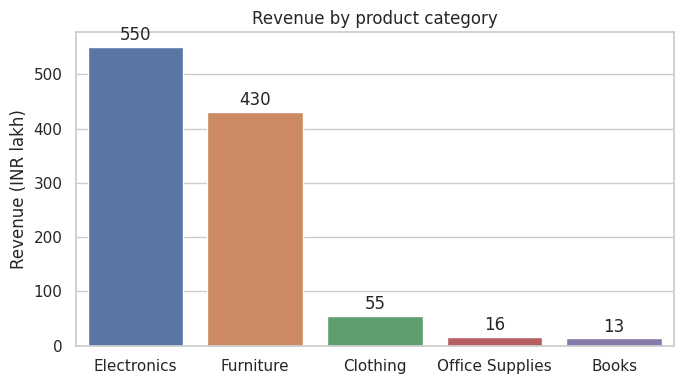

In [16]:
# 1. BAR CHART (Seaborn): revenue by category
cat_rev = sales.groupby("category", as_index=False)["revenue"].sum().sort_values("revenue", ascending=False)
cat_rev["revenue_lakh"] = cat_rev["revenue"] / 1e5
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=cat_rev, x="category", y="revenue_lakh", hue="category", legend=False, ax=ax)
for c in ax.containers: ax.bar_label(c, fmt="%.0f", padding=2)
ax.set(title="Revenue by product category", xlabel="", ylabel="Revenue (INR lakh)")
save_fig(fig, "01_bar_revenue_by_category.png")

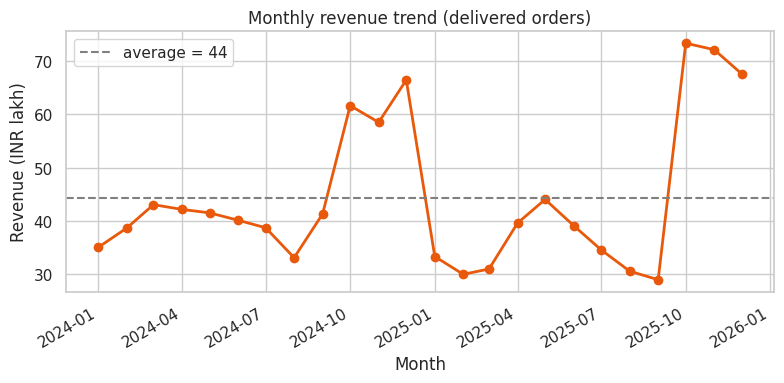

In [17]:
# 2. LINE CHART (Matplotlib): monthly revenue trend
monthly = sales.groupby("month")["revenue"].sum() / 1e5
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(monthly.index, monthly.values, marker="o", lw=2, color="#E8590C")
ax.set(title="Monthly revenue trend (delivered orders)", xlabel="Month", ylabel="Revenue (INR lakh)")
ax.axhline(monthly.mean(), ls="--", color="grey", label=f"average = {monthly.mean():.0f}"); ax.legend()
fig.autofmt_xdate()
save_fig(fig, "02_line_monthly_revenue.png")

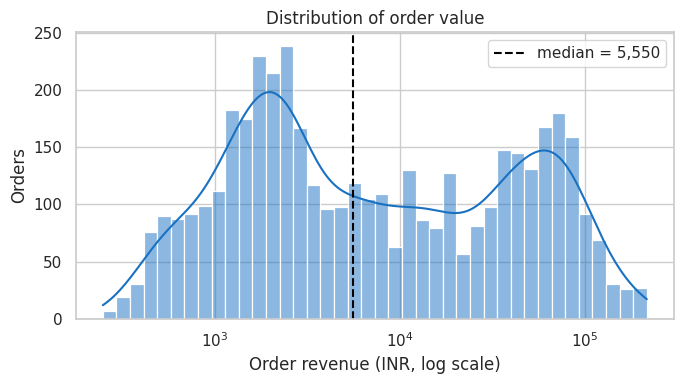

In [18]:
# 3. HISTOGRAM: distribution of order value (log scale because of heavy right skew)
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(sales["revenue"], bins=40, log_scale=True, kde=True, ax=ax, color="#1971C2")
ax.axvline(sales["revenue"].median(), color="black", ls="--", label=f"median = {sales['revenue'].median():,.0f}")
ax.set(title="Distribution of order value", xlabel="Order revenue (INR, log scale)", ylabel="Orders"); ax.legend()
save_fig(fig, "03_hist_order_value.png")

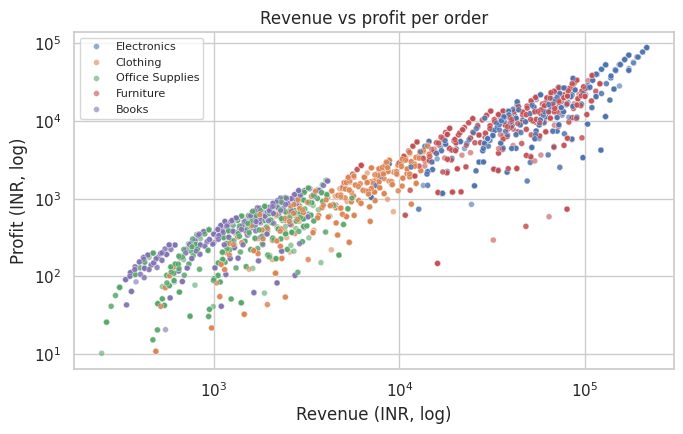

In [19]:
# 4. SCATTER PLOT: order revenue vs profit coloured by category
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=sales, x="revenue", y="profit", hue="category", s=18, alpha=.6, ax=ax)
ax.set(xscale="log", yscale="log", title="Revenue vs profit per order", xlabel="Revenue (INR, log)", ylabel="Profit (INR, log)")
ax.legend(fontsize=8, loc="upper left")
save_fig(fig, "04_scatter_revenue_profit.png")

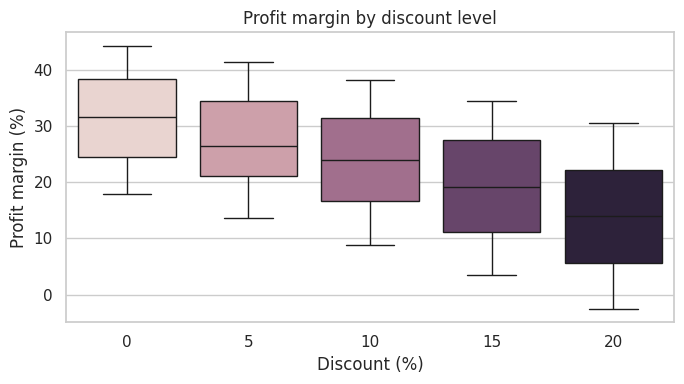

In [20]:
# 5. BOX PLOT: profit margin by discount level
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=sales, x=(sales["discount"] * 100).astype(int), y="margin_pct", hue=(sales["discount"] * 100).astype(int), legend=False, ax=ax)
ax.set(title="Profit margin by discount level", xlabel="Discount (%)", ylabel="Profit margin (%)")
save_fig(fig, "05_box_margin_by_discount.png")

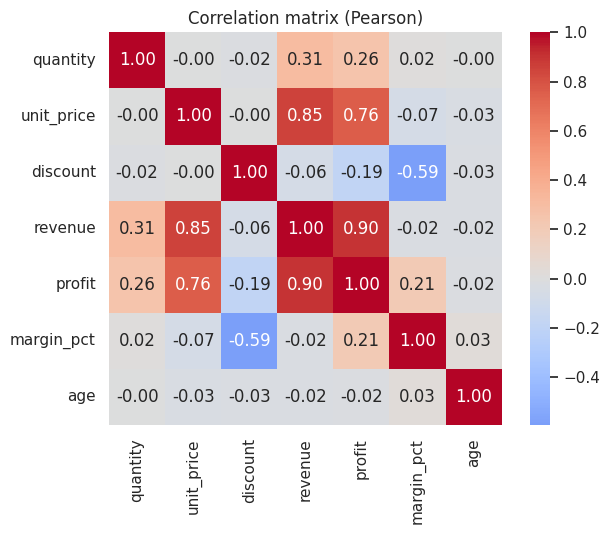

In [21]:
# 6. HEATMAP: correlation matrix
num_cols = ["quantity", "unit_price", "discount", "revenue", "profit", "margin_pct", "age"]
corr = sales[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation matrix (Pearson)")
save_fig(fig, "06_heatmap_correlation.png")

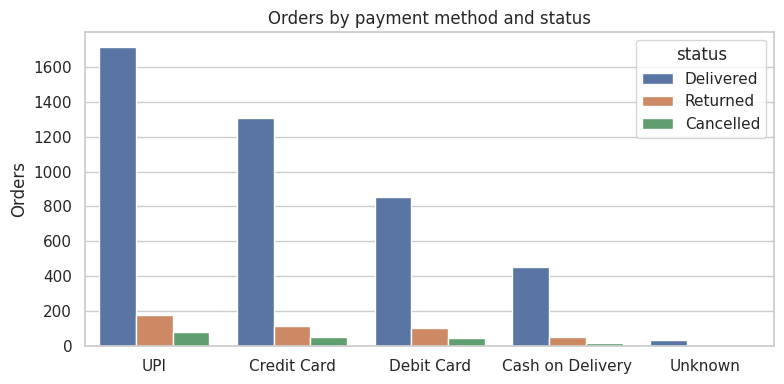

In [22]:
# 7. COUNT PLOT: orders by payment method and status
fig, ax = plt.subplots(figsize=(8, 4))
order = df["payment_method"].value_counts().index
sns.countplot(data=df, x="payment_method", hue="status", order=order, ax=ax)
ax.set(title="Orders by payment method and status", xlabel="", ylabel="Orders")
save_fig(fig, "07_count_payment_status.png")

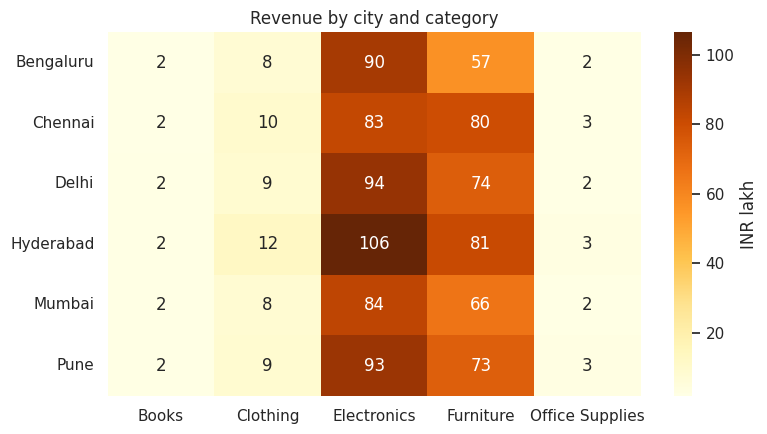

In [23]:
# 8. HEATMAP: revenue by city and category (pivot table)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot / 1e5, annot=True, fmt=".0f", cmap="YlOrBr", ax=ax, cbar_kws={"label": "INR lakh"})
ax.set(title="Revenue by city and category", xlabel="", ylabel="")
save_fig(fig, "08_heatmap_city_category.png")

## Part 5 - Basic data analysis
### 5.1 Descriptive statistics and distributions

In [24]:
desc = sales[["quantity", "unit_price", "discount", "revenue", "profit", "margin_pct"]].describe().T.round(2)
desc["skew"] = sales[desc.index].skew().round(2)
display(desc)
rev = sales["revenue"]
q1, q3 = rev.quantile([.25, .75]); iqr = q3 - q1
n_out = int(((rev < q1 - 1.5 * iqr) | (rev > q3 + 1.5 * iqr)).sum())
print(f"Revenue: mean {rev.mean():,.0f} vs median {rev.median():,.0f} | skew {rev.skew():.2f} | IQR outliers {n_out} ({n_out / len(rev):.1%})")
print(f"log-transform reduces skew from {rev.skew():.2f} to {np.log(rev).skew():.2f}")
METRICS.update(delivered_orders=int(len(sales)), total_revenue=float(rev.sum()), total_profit=float(sales["profit"].sum()),
               overall_margin=float(sales["profit"].sum() / rev.sum() * 100), mean_order=float(rev.mean()), median_order=float(rev.median()),
               revenue_skew=float(rev.skew()), log_revenue_skew=float(np.log(rev).skew()), revenue_outliers=n_out)

,count,mean,std,min,25%,50%,75%,max,skew
quantity,4362.0,3.01,1.40,1.00,2.00,3.00,4.00,5.00,-0.02
unit_price,4362.0,8746.96,11158.85,309.00,615.00,2587.00,17143.00,43290.00,1.39
discount,4362.0,0.07,0.07,0.00,0.00,0.05,0.15,0.20,0.50
revenue,4362.0,24408.85,36092.06,247.20,1740.08,5550.00,36323.10,216450.00,2.11
profit,4362.0,6136.26,10980.87,-2979.00,419.95,1246.20,7680.00,88400.00,3.45
margin_pct,4362.0,25.54,10.82,-2.58,18.36,25.95,34.27,44.41,-0.32


Revenue: mean 24,409 vs median 5,550 | skew 2.11 | IQR outliers 279 (6.4%)
log-transform reduces skew from 2.11 to 0.16


### 5.2 Relationships and correlations

In [25]:
r_qty_rev  = sales["quantity"].corr(sales["revenue"])
r_price_rev = sales["unit_price"].corr(sales["revenue"], method="spearman")
r_disc_marg = sales["discount"].corr(sales["margin_pct"])
r_age_rev  = sales["age"].corr(sales["revenue"], method="spearman")
print(f"quantity   vs revenue (Pearson) : {r_qty_rev:6.3f}")
print(f"unit_price vs revenue (Spearman): {r_price_rev:6.3f}")
print(f"discount   vs margin  (Pearson) : {r_disc_marg:6.3f}")
print(f"age        vs revenue (Spearman): {r_age_rev:6.3f}   <- close to 0: age does not drive spend")
METRICS.update(r_qty_rev=r_qty_rev, r_price_rev=r_price_rev, r_disc_marg=r_disc_marg, r_age_rev=r_age_rev)

quantity   vs revenue (Pearson) :  0.313
unit_price vs revenue (Spearman):  0.918
discount   vs margin  (Pearson) : -0.594
age        vs revenue (Spearman): -0.008   <- close to 0: age does not drive spend


### 5.3 Patterns: seasonality, segments, cities

In [26]:
monthly_all = sales.groupby("month")["revenue"].sum()
q4 = monthly_all[monthly_all.index.month >= 10].mean(); rest = monthly_all[monthly_all.index.month < 10].mean()
print(f"Average monthly revenue  Oct-Dec: {q4 / 1e5:,.1f} lakh | Jan-Sep: {rest / 1e5:,.1f} lakh | uplift {q4 / rest - 1:.0%}")

seg = sales.groupby("segment").agg(orders=("order_id", "count"), avg_order=("revenue", "mean"), margin=("margin_pct", "mean")).round(1)
display(seg)
wk = sales.groupby("weekday")["revenue"].sum().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
print("Weekday revenue spread (max/min):", round(wk.max() / wk.min(), 2))
city = sales.groupby("city")["revenue"].sum().sort_values(ascending=False)
print("Top city:", city.index[0], f"({city.iloc[0] / city.sum():.1%} of revenue)")

top_cat = by_cat.index[0]
METRICS.update(q4_avg=float(q4), rest_avg=float(rest), q4_uplift=float(q4 / rest - 1), top_category=top_cat,
               top_category_share=float(by_cat.loc[top_cat, "revenue"] / by_cat["revenue"].sum() * 100),
               top_city=city.index[0], top_city_share=float(city.iloc[0] / city.sum() * 100),
               category_margins={k: float(v) for k, v in by_cat["margin_pct"].items()},
               return_rate=float((df["status"] == "Returned").mean() * 100), cancel_rate=float((df["status"] == "Cancelled").mean() * 100),
               weekday_ratio=float(wk.max() / wk.min()))

Average monthly revenue  Oct-Dec: 66.6 lakh | Jan-Sep: 37.0 lakh | uplift 80%


,orders,avg_order,margin
segment,,,
Consumer,2273,24664.9,25.7
Corporate,1454,24067.6,25.3
Home Office,529,24381.5,25.5
Unknown,106,23735.7,25.5


Weekday revenue spread (max/min): 1.14
Top city: Hyderabad (19.4% of revenue)


### 5.4 Simple statistical tests

In [27]:
# Welch t-test: do discounted orders have a lower margin?
disc, nodisc = sales.loc[sales["discount"] > 0, "margin_pct"], sales.loc[sales["discount"] == 0, "margin_pct"]
t, p = stats.ttest_ind(disc, nodisc, equal_var=False)
print(f"Mean margin: discounted {disc.mean():.1f}% vs full price {nodisc.mean():.1f}%  (t = {t:.1f}, p = {p:.2g})")

# Chi-square: is payment method associated with order status?
chi2, p_chi, dof, _ = stats.chi2_contingency(pd.crosstab(df["payment_method"], df["status"]))
print(f"Payment method vs status: chi2 = {chi2:.1f}, dof = {dof}, p = {p_chi:.2f}  -> {'association' if p_chi < .05 else 'no evidence of association'}")
METRICS.update(margin_discounted=float(disc.mean()), margin_full=float(nodisc.mean()), ttest_p=float(p), chi2_p=float(p_chi))

Mean margin: discounted 21.1% vs full price 31.5%  (t = -37.2, p = 8.2e-264)
Payment method vs status: chi2 = 8.4, dof = 8, p = 0.39  -> no evidence of association


### 5.5 Scikit-learn smoke test
Confirms scikit-learn works end to end (split, scale, fit, score). This is an environment check, not a modelling claim: revenue is mathematically derived from these features, so a high R-squared is expected.

In [28]:
X = sales[["quantity", "unit_price", "discount"]]; y = sales["revenue"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.25, random_state=SEED)
sc = StandardScaler().fit(X_tr)
model = LinearRegression().fit(sc.transform(X_tr), y_tr)
r2 = r2_score(y_te, model.predict(sc.transform(X_te)))
print(f"Linear regression test R-squared: {r2:.3f}")
print(dict(zip(X.columns, model.coef_.round(0))))
METRICS["sklearn_r2"] = float(r2)

Linear regression test R-squared: 0.821
{'quantity': np.float64(11313.0), 'unit_price': np.float64(31290.0), 'discount': np.float64(-1997.0)}


## Part 6 - Observations and insights

In [29]:
M = METRICS
print(f"1. Revenue and profit : INR {M['total_revenue'] / 1e7:.2f} crore revenue, {M['overall_margin']:.1f}% margin across {M['delivered_orders']:,} delivered orders.")
print(f"2. Category mix       : {M['top_category']} brings {M['top_category_share']:.0f}% of revenue; margins range {min(M['category_margins'].values()):.0f}%-{max(M['category_margins'].values()):.0f}%.")
print(f"3. Seasonality        : Oct-Dec months earn {M['q4_uplift']:.0%} more than Jan-Sep months on average.")
print(f"4. Discounts          : discounted orders average {M['margin_discounted']:.1f}% margin vs {M['margin_full']:.1f}% at full price (p {'< 0.001' if M['ttest_p'] < 0.001 else '= %.3f' % M['ttest_p']}).")
print(f"5. Skewed order value : mean {M['mean_order']:,.0f} vs median {M['median_order']:,.0f}; use the median and log scales for typical order size.")
print(f"6. Non-findings       : age vs revenue rho = {M['r_age_rev']:.2f}; payment method vs status p = {M['chi2_p']:.2f}. Not every variable matters.")
print(f"7. Operations         : {M['return_rate']:.1f}% of orders returned and {M['cancel_rate']:.1f}% cancelled.")

1. Revenue and profit : INR 10.65 crore revenue, 25.1% margin across 4,362 delivered orders.
2. Category mix       : Electronics brings 52% of revenue; margins range 24%-32%.
3. Seasonality        : Oct-Dec months earn 80% more than Jan-Sep months on average.
4. Discounts          : discounted orders average 21.1% margin vs 31.5% at full price (p < 0.001).
5. Skewed order value : mean 24,409 vs median 5,550; use the median and log scales for typical order size.
6. Non-findings       : age vs revenue rho = -0.01; payment method vs status p = 0.39. Not every variable matters.
7. Operations         : 9.0% of orders returned and 3.8% cancelled.


### Recommendations
1. **Plan stock and campaigns for Q4**, which is the clearest seasonal peak.
2. **Limit deep discounts**: they cut margin, yet average quantity per order stays flat at about 3 units across all discount levels, so there is no sign that discounts lift basket size. Test targeted rather than blanket discounts.
3. **Report medians** (and log-scaled charts) for order value because a few very large orders dominate the mean.
4. **Investigate returns**: the return rate is more than twice the cancellation rate, so review it by category before the next season.

### Limitations
The data is synthetic, so patterns reflect how it was generated and illustrate technique rather than real business facts. Correlation is not causation, and the regression is only an environment smoke test.

### Reproducibility checklist
- Fixed seeds (`SEED = 7`), versions printed in Part 1, dependencies in `requirements.txt`
- Cleaning rules documented and enforced with assertions
- Notebook runs top-to-bottom from the raw CSVs without manual steps

In [30]:
df.to_csv(ROOT / "data" / "retail_clean_merged.csv", index=False)
(ROOT / "outputs" / "key_metrics.json").write_text(json.dumps(METRICS, indent=2, default=float))
print("Saved cleaned dataset and key_metrics.json")

Saved cleaned dataset and key_metrics.json
